# Stage 2: QA, fixed support and prepared series

Read the candidate `prep-1.0.0` preparation outputs. Strict MODIS QA excludes marginal/cloud/snow/historical-fill observations. Only cells valid in every registered reference month are retained for the analysis series. Annual summaries require all 12 months. The policy awaits owner review; there are no slopes, p-values or confidence claims here.

Generate inputs first with `tools/prepare_science_inputs.py`, generate the explicit standard-mode MODIS comparison, and run `tools/validate_prepared_inputs.py`. See the Stage 2 report for complete commands.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/architecture/scope.v2.json").exists())
sys.path.insert(0, str(root / "packages/science"))
from src.preprocessing import load_policy, policy_hash
report = json.loads((root / "packages/science/phase_reports/PHASE_2_COVERAGE.json").read_text(encoding="utf-8"))
comparison = json.loads((root / "packages/science/phase_reports/PHASE_2_QA_SENSITIVITY.json").read_text(encoding="utf-8"))
assert report["policy_sha256"] == policy_hash(load_policy())
assert len(report["entries"]) == 12
for entry in report["entries"]:
    artifact = root / entry["artifact"]
    assert hashlib.sha256(artifact.read_bytes()).hexdigest() == entry["artifact_sha256"]
output = root / "data/derived/science/phase_2"
output.mkdir(parents=True, exist_ok=True)
labels = {"air_temperature": "Air temperature", "soil_moisture": "Soil moisture", "precipitation": "Precipitation", "vegetation_greenness": "NDVI"}
region_labels = {"nile_corridor": "Nile", "morocco_comparison": "Morocco", "sahel_comparison": "Sahel"}
for entry in report["entries"]:
    print(f"{labels[entry['variable_id']]} | {region_labels[entry['region_id']]}: {entry['eligible_fixed_support_cells']}/{entry['selected_cell_count']} fixed cells; retained area {entry['fixed_support_area_fraction_of_selected_native_cells']:.2%}; state={entry['preparation_state']}")

Air temperature | Nile: 102/102 fixed cells; retained area 100.00%; state=prepared
Soil moisture | Nile: 459/512 fixed cells; retained area 89.98%; state=prepared
Precipitation | Nile: 3200/3200 fixed cells; retained area 100.00%; state=prepared
NDVI | Nile: 7302/12800 fixed cells; retained area 57.50%; state=prepared
Air temperature | Morocco: 80/80 fixed cells; retained area 100.00%; state=prepared
Soil moisture | Morocco: 287/400 fixed cells; retained area 72.13%; state=prepared
Precipitation | Morocco: 2500/2500 fixed cells; retained area 100.00%; state=prepared
NDVI | Morocco: 3019/10000 fixed cells; retained area 30.62%; state=prepared
Air temperature | Sahel: 160/160 fixed cells; retained area 100.00%; state=prepared
Soil moisture | Sahel: 800/800 fixed cells; retained area 100.00%; state=prepared
Precipitation | Sahel: 5000/5000 fixed cells; retained area 100.00%; state=prepared
NDVI | Sahel: 2961/20000 fixed cells; retained area 14.69%; state=prepared


## 0. Preprocessing: compare the three Sahel NDVI outputs

This section compares the **three policies recommended in the checkpoint**:

| Output | Quality rule | Cell eligibility across January 2001?December 2024 |
|---|---|---|
| Strict 100% ? existing default | Good MODLAND flag and good reliability | All 288 months pass QA |
| Standard 100% ? comparison | Good or marginal MODLAND/reliability | All 288 months pass QA |
| Standard 95% ? experimental | Same standard QA | At least 274 of 288 months pass QA |

**NDVI** is a unitless indicator of vegetation greenness. **QA** means quality assessment.
A **cell** is one native map-grid square. A **cell-month** is one cell in one month.
?Eligible area? describes the footprint selected over all 24 years; ?observed area?
describes the eligible cells with a valid value in a particular month.

The original source is shown for context. Its finite values have not passed our QA policy;
it is not a fourth approved output or a truth reference. The experimental 90% case remains
in the checkpoint and is not one of these three recommended comparisons.

This section reads existing files and does not regenerate data or change the default.
If the experimental files are missing, run `tools/review_sahel_ndvi.py` first.
The tables and plots below contain actual values calculated from the prepared files.

In [2]:
import pandas as pd
from IPython.display import HTML
from src.data_loader import input_entry, load_cube
from src.qa_policy_review import SEASONS

sahel_metrics = json.loads((root / "packages/science/phase_reports/SAHEL_NDVI_POLICY_METRICS.json").read_text(encoding="utf-8"))
sahel_specs = {
    "strict_100": {"label": "Strict 100% (default)", "color": "#2563eb", "record": strict_record}
    for strict_record in report["entries"]
    if strict_record["variable_id"] == "vegetation_greenness" and strict_record["region_id"] == "sahel_comparison"
}
sahel_specs["standard_100"] = {
    "label": "Standard 100%", "color": "#e8790c",
    "record": next(e for e in comparison["entries"] if e["region_id"] == "sahel_comparison"),
}
sahel_specs["standard_95"] = {
    "label": "Standard 95% (experimental)", "color": "#15956f",
    "record": sahel_metrics["cases"]["standard_95"],
}
sahel_cases = {}
for sahel_key, sahel_spec in sahel_specs.items():
    sahel_path = root / sahel_spec["record"]["artifact"]
    if not sahel_path.is_file():
        raise FileNotFoundError(f"Existing prepared artifact required: {sahel_path}")
    assert hashlib.sha256(sahel_path.read_bytes()).hexdigest() == sahel_spec["record"]["artifact_sha256"]
    with xr.open_dataset(sahel_path) as sahel_open:
        sahel_support_name = "eligible_support" if sahel_key == "standard_95" else "fixed_support"
        sahel_cases[sahel_key] = sahel_open[["cell_monthly", "regional_monthly", "qa_accepted",
                                          "native_cell_solid_angle", sahel_support_name]].load()
        sahel_cases[sahel_key] = sahel_cases[sahel_key].rename({sahel_support_name: "eligible"})

sahel_entry = input_entry("vegetation_greenness", "sahel_comparison")
assert hashlib.sha256((root / sahel_entry["cube_file"]).read_bytes()).hexdigest() == sahel_metrics["source_sha256"]
sahel_source = load_cube("vegetation_greenness", "sahel_comparison")
sahel_weights = sahel_cases["strict_100"].native_cell_solid_angle
sahel_source_mean = (sahel_source.NDVI * sahel_weights).sum(("lat", "lon")) / sahel_weights.sum()
sahel_display_output = root / "data/derived/science/sahel_ndvi_preprocessing_comparison"
sahel_display_output.mkdir(parents=True, exist_ok=True)

def sahel_show_table(frame):
    display(HTML(frame.to_html(index=False, na_rep="missing", float_format=lambda value: f"{value:.6f}")))

print(f"Source: MOD13C2 Collection 6.1 | {sahel_source.sizes['time']} months | "
      f"{sahel_source.sizes['lat']} x {sahel_source.sizes['lon']} native cells | NDVI units: 1")
print(f"Period: {sahel_entry['period'][0]} to {sahel_entry['period'][1]}; bbox: {sahel_entry['bbox']}")
print("Verified source and all three artifact hashes. No preparation files were rewritten.")

Source: MOD13C2 Collection 6.1 | 288 months | 100 x 200 native cells | NDVI units: 1
Period: 2001-01 to 2024-12; bbox: [-5, 12, 5, 17]
Verified source and all three artifact hashes. No preparation files were rewritten.


### 0.1 How much data does each output keep?

**Area percentages** use the spherical area of all 20,000 selected native cells,
not the number of cells and not an exact country boundary. **Kept cell-months** count
finite prepared cell values. An output can have a complete 288-point regional series
while individual cells contain gaps. Missing values are never replaced with zeros.

In [3]:
sahel_summary_rows = []
sahel_observed = {}
sahel_observed_area = {}
for sahel_key, sahel_ds in sahel_cases.items():
    sahel_mask = np.isfinite(sahel_ds.cell_monthly)
    sahel_eligible = sahel_ds.eligible.astype(bool)
    sahel_observed[sahel_key] = sahel_mask
    sahel_observed_area[sahel_key] = (sahel_weights.where(sahel_mask, 0).sum(("lat", "lon")) / sahel_weights.sum()).clip(0, 1)
    sahel_eligible_area = float(sahel_weights.where(sahel_eligible, 0).sum() / sahel_weights.sum())
    sahel_stat = sahel_metrics["cases"][sahel_key]
    assert int(sahel_eligible.sum()) == sahel_stat["eligible_cell_count"]
    np.testing.assert_allclose(sahel_eligible_area, sahel_stat["eligible_area_fraction_selected"], atol=1e-12)
    np.testing.assert_allclose(sahel_ds.regional_monthly, [r["regional_ndvi"] for r in sahel_stat["monthly"]], atol=1e-12)
    np.testing.assert_array_equal(sahel_mask, sahel_ds.qa_accepted.astype(bool) & sahel_eligible)
    np.testing.assert_array_equal(sahel_ds.cell_monthly.values[sahel_mask.values], sahel_source.NDVI.values[sahel_mask.values])
    sahel_summary_rows.append({
        "Output": sahel_specs[sahel_key]["label"],
        "Required valid months / 288": sahel_stat["required_valid_months"],
        "Eligible cells / 20000": int(sahel_eligible.sum()),
        "Eligible area %": sahel_eligible_area * 100,
        "Mean observed area %": float(sahel_observed_area[sahel_key].mean()) * 100,
        "Worst observed area %": float(sahel_observed_area[sahel_key].min()) * 100,
        "Kept cell-months / 5760000": int(sahel_mask.sum()),
        "Regional valid months / 288": int(sahel_ds.regional_monthly.notnull().sum()),
    })
sahel_coverage_comparison = pd.DataFrame(sahel_summary_rows)
sahel_show_table(sahel_coverage_comparison)
print("Source context: 20,000 cells; 5,760,000 finite values before QA. Finite does not mean good quality.")

Output,Required valid months / 288,Eligible cells / 20000,Eligible area %,Mean observed area %,Worst observed area %,Kept cell-months / 5760000,Regional valid months / 288
Strict 100% (default),288,2961,14.694806,14.694806,14.694806,852768,288
Standard 100%,288,16531,82.586861,82.586861,82.586861,4760928,288
Standard 95% (experimental),274,19995,99.975148,99.883173,94.669775,5753281,288


Source context: 20,000 cells; 5,760,000 finite values before QA. Finite does not mean good quality.


### 0.2 Compare the regional data and seasonal cycle

The gray source line is an area-weighted mean before our QA filtering.
The three colored lines average their own retained observations. Differences combine
quality eligibility and geography; they are not measurements of error or statistical significance.
The seasonal-cycle panel averages each calendar month over 2001?2024. The gap panel
uses each policy's own eligible area as its denominator.

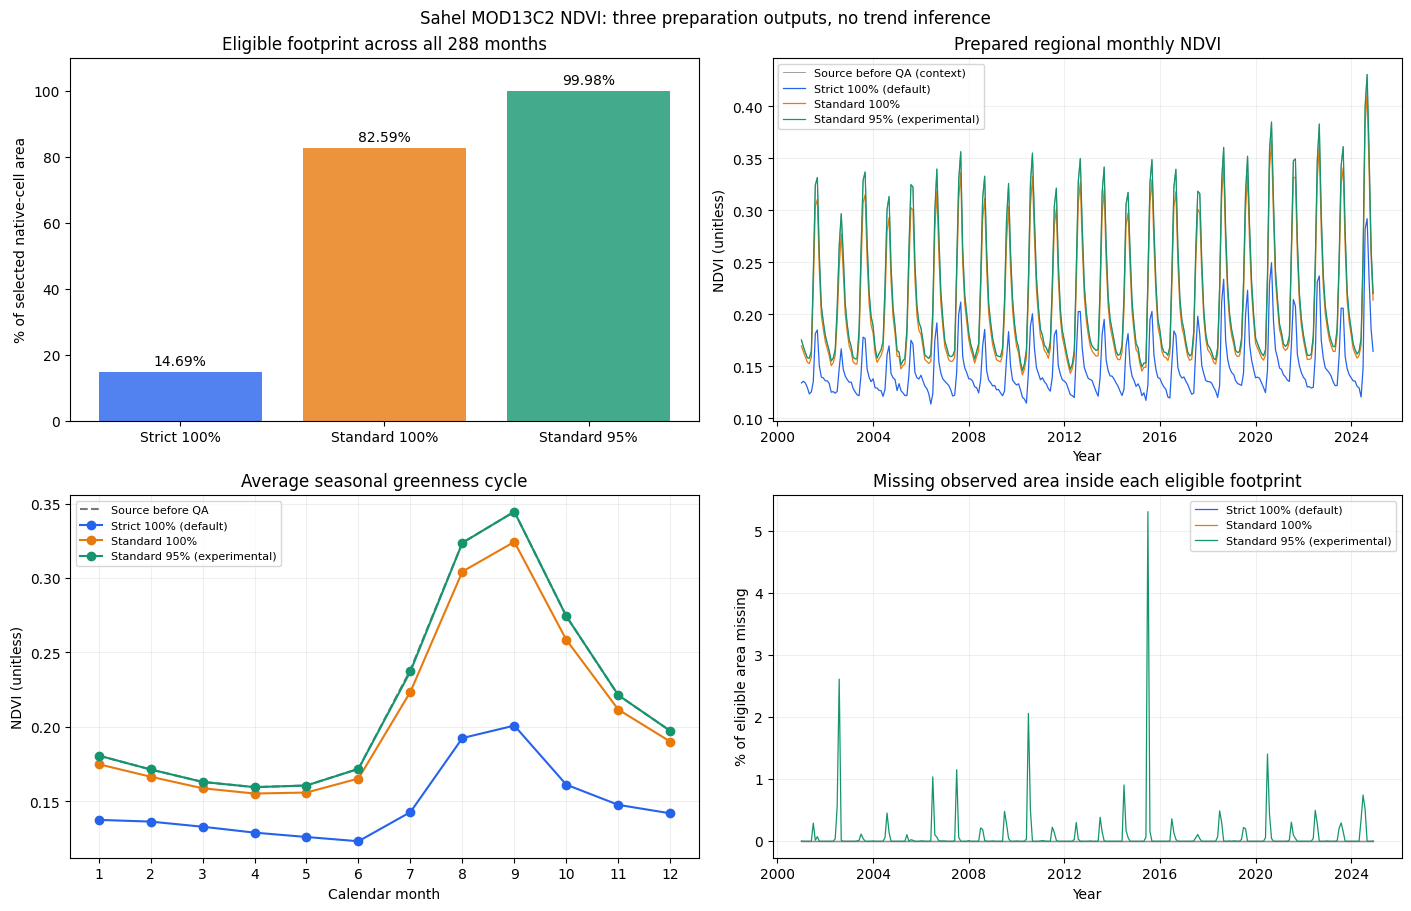

In [4]:
sahel_fig, sahel_axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")
sahel_x = np.arange(3)
sahel_short_labels = ["Strict 100%", "Standard 100%", "Standard 95%"]
sahel_colors = [s["color"] for s in sahel_specs.values()]
sahel_bars = sahel_axes[0, 0].bar(sahel_x, sahel_coverage_comparison["Eligible area %"], color=sahel_colors, alpha=.8)
sahel_axes[0, 0].bar_label(sahel_bars, fmt="%.2f%%", padding=3)
sahel_axes[0, 0].set(xticks=sahel_x, xticklabels=sahel_short_labels, ylim=(0, 110),
                     ylabel="% of selected native-cell area", title="Eligible footprint across all 288 months")
sahel_axes[0, 1].plot(sahel_source.time, sahel_source_mean, color="#777777", linewidth=.7, alpha=.7, label="Source before QA (context)")
sahel_axes[1, 0].plot(np.arange(1, 13), sahel_source_mean.groupby("time.month").mean(), color="#777777", linestyle="--", label="Source before QA")
for sahel_key, sahel_ds in sahel_cases.items():
    sahel_label, sahel_color = sahel_specs[sahel_key]["label"], sahel_specs[sahel_key]["color"]
    sahel_axes[0, 1].plot(sahel_ds.time, sahel_ds.regional_monthly, label=sahel_label, color=sahel_color, linewidth=.9)
    sahel_axes[1, 0].plot(np.arange(1, 13), sahel_ds.regional_monthly.groupby("time.month").mean(), "o-", color=sahel_color, label=sahel_label)
    sahel_footprint_area = float(sahel_weights.where(sahel_ds.eligible.astype(bool), 0).sum() / sahel_weights.sum())
    sahel_gap_pct = (1 - sahel_observed_area[sahel_key] / sahel_footprint_area).clip(0, 1) * 100
    sahel_axes[1, 1].plot(sahel_ds.time, sahel_gap_pct, label=sahel_label, color=sahel_color, linewidth=.9)
sahel_axes[0, 1].set(title="Prepared regional monthly NDVI", xlabel="Year", ylabel="NDVI (unitless)")
sahel_axes[1, 0].set(title="Average seasonal greenness cycle", xlabel="Calendar month", ylabel="NDVI (unitless)", xticks=np.arange(1, 13))
sahel_axes[1, 1].set(title="Missing observed area inside each eligible footprint", xlabel="Year", ylabel="% of eligible area missing")
for sahel_ax in (sahel_axes[0, 1], sahel_axes[1, 0], sahel_axes[1, 1]):
    sahel_ax.grid(alpha=.2)
    sahel_ax.legend(fontsize=8)
sahel_fig.suptitle("Sahel MOD13C2 NDVI: three preparation outputs, no trend inference")
sahel_fig.savefig(sahel_display_output / "three_output_comparison.png", dpi=140)
display(sahel_fig)
plt.close(sahel_fig)

### 0.3 Where do the observations come from?

Yellow cells are eligible and blue cells are excluded. Strict complete coverage is
concentrated in the north; standard policies include more southern cells. The standard
95% map shows **eligibility**, not a promise that all of those cells are observed in every month.

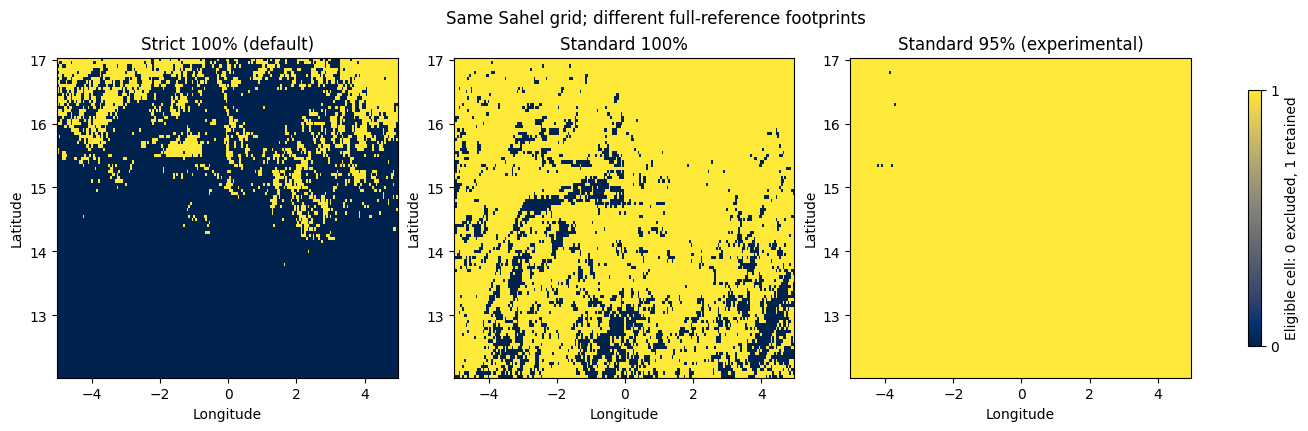

Output,DJF missing eligible area-time %,MAM missing eligible area-time %,JJA missing eligible area-time %,SON missing eligible area-time %
Strict 100% (default),0.000000,0.000000,0.000000,0.000000
Standard 100%,0.000000,0.000000,0.000000,0.000000
Standard 95% (experimental),0.001241,0.000208,0.355738,0.010804


DJF: Dec-Feb; MAM: Mar-May; JJA: Jun-Aug; SON: Sep-Nov. Pooled calendar groups, not local climate-season classifications.


In [5]:
sahel_fig, sahel_axes = plt.subplots(1, 3, figsize=(13, 4.2), layout="constrained")
for sahel_ax, (sahel_key, sahel_ds) in zip(sahel_axes, sahel_cases.items()):
    sahel_image = sahel_ax.pcolormesh(sahel_ds.lon, sahel_ds.lat, sahel_ds.eligible, cmap="cividis", vmin=0, vmax=1, shading="auto")
    sahel_ax.set(title=sahel_specs[sahel_key]["label"], xlabel="Longitude", ylabel="Latitude")
sahel_fig.colorbar(sahel_image, ax=sahel_axes.tolist(), ticks=[0, 1], label="Eligible cell: 0 excluded, 1 retained", shrink=.8)
sahel_fig.suptitle("Same Sahel grid; different full-reference footprints")
sahel_fig.savefig(sahel_display_output / "three_output_footprints.png", dpi=140)
display(sahel_fig)
plt.close(sahel_fig)

sahel_season_rows = []
for sahel_key in sahel_cases:
    sahel_season_rows.append({"Output": sahel_specs[sahel_key]["label"], **{
        f"{season} missing eligible area-time %": sahel_metrics["cases"][sahel_key]["missingness"]["season"][season]["missing_area_time_fraction"] * 100
        for season in SEASONS
    }})
sahel_show_table(pd.DataFrame(sahel_season_rows))
print("DJF: Dec-Feb; MAM: Mar-May; JJA: Jun-Aug; SON: Sep-Nov. Pooled calendar groups, not local climate-season classifications.")

### 0.4 Inspect the actual monthly regional data

`sahel_monthly_data` holds **all 288 rows** for further inspection. This preview shows
the first year plus July 2015, the worst observed-area month in standard 95%.
Each NDVI column is a regional monthly mean; the final column reports how much of
the original selected area actually contributed to standard 95% that month.

Month,Source mean before QA (NDVI),Strict 100% NDVI,Standard 100% NDVI,Standard 95% NDVI,Standard 95% observed area %
2001-01,0.175459,0.134170,0.169686,0.175469,99.970187
2001-02,0.168642,0.135772,0.163916,0.168652,99.975148
2001-03,0.163517,0.134121,0.159210,0.163516,99.975148
2001-04,0.158335,0.129897,0.154171,0.158327,99.975148
2001-05,0.157861,0.123577,0.152774,0.157867,99.975148
2001-06,0.164433,0.125516,0.158595,0.164439,99.975148
2001-07,0.239879,0.135432,0.224222,0.239457,99.683146
2001-08,0.324344,0.181596,0.304273,0.324383,99.960162
2001-09,0.331594,0.185077,0.310550,0.331637,99.900625
2001-10,0.257813,0.150671,0.243042,0.257822,99.975148


Full monthly data available as sahel_monthly_data: 288 rows.


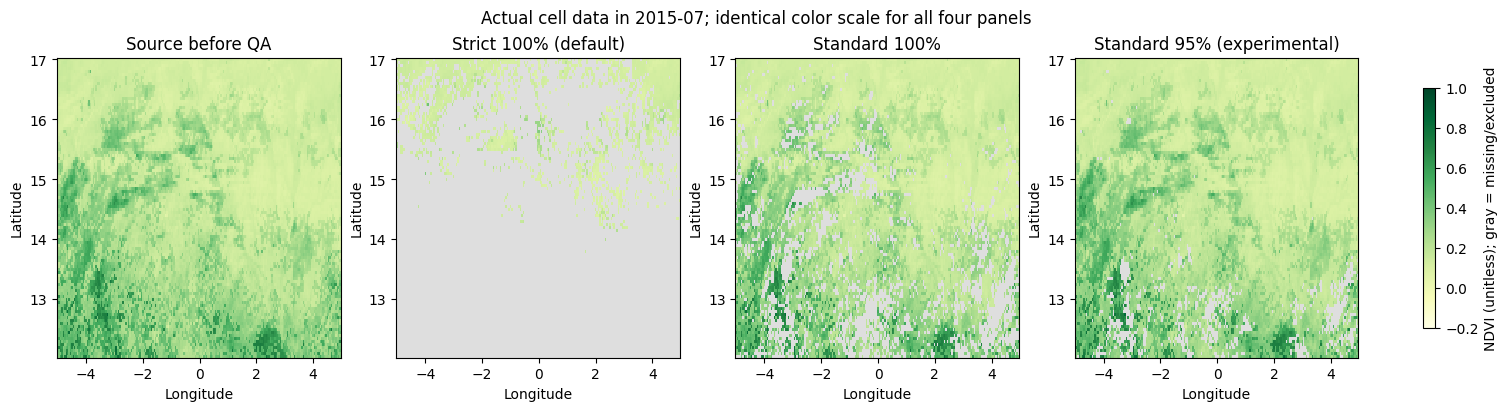

In [6]:
sahel_monthly_data = pd.DataFrame({
    "Month": sahel_source.time.dt.strftime("%Y-%m").values,
    "Source mean before QA (NDVI)": sahel_source_mean.values,
    **{f"{sahel_short_labels[i]} NDVI": sahel_cases[key].regional_monthly.values
       for i, key in enumerate(sahel_cases)},
    "Standard 95% observed area %": sahel_observed_area["standard_95"].values * 100,
})
sahel_worst_month = min(sahel_metrics["cases"]["standard_95"]["monthly"], key=lambda row: row["observed_area_fraction_selected"])["month"]
sahel_preview = (sahel_monthly_data["Month"] <= "2001-12") | (sahel_monthly_data["Month"] == sahel_worst_month)
sahel_show_table(sahel_monthly_data.loc[sahel_preview])
print(f"Full monthly data available as sahel_monthly_data: {len(sahel_monthly_data)} rows.")

sahel_fig, sahel_axes = plt.subplots(1, 4, figsize=(15, 4), layout="constrained")
sahel_map_arrays = [("Source before QA", sahel_source.NDVI.sel(time=sahel_worst_month).squeeze())] + [
    (sahel_specs[key]["label"], ds.cell_monthly.sel(time=sahel_worst_month).squeeze()) for key, ds in sahel_cases.items()]
sahel_cmap = plt.get_cmap("YlGn").copy()
sahel_cmap.set_bad("#dedede")
for sahel_ax, (sahel_label, sahel_values) in zip(sahel_axes, sahel_map_arrays):
    sahel_image = sahel_ax.pcolormesh(sahel_values.lon, sahel_values.lat, sahel_values, cmap=sahel_cmap, vmin=-.2, vmax=1, shading="auto")
    sahel_ax.set(title=sahel_label, xlabel="Longitude", ylabel="Latitude")
sahel_fig.colorbar(sahel_image, ax=sahel_axes.tolist(), label="NDVI (unitless); gray = missing/excluded", shrink=.8)
sahel_fig.suptitle(f"Actual cell data in {sahel_worst_month}; identical color scale for all four panels")
sahel_fig.savefig(sahel_display_output / "source_and_prepared_month.png", dpi=140)
display(sahel_fig)
plt.close(sahel_fig)

### 0.5 Inspect actual cell values: why does a value disappear?

The following are deliberately selected examples of different QA/support outcomes,
not a random or representative sample. `Source NDVI` is the delivered value before
our filtering. `VI quality word` stores several bit fields; `MODLAND code` is its
lowest two bits. Reliability 0 means good, 1 marginal, and 4 historical estimation.
**missing** in a prepared column is an excluded or unavailable observation, never zero.
A currently good observation can still be excluded if its cell failed another month
and therefore did not qualify for that output's full-reference footprint.

In [7]:
sahel_cell_rows = []
sahel_worst_i = int(np.flatnonzero(sahel_monthly_data["Month"].values == sahel_worst_month)[0])
sahel_strict_support = sahel_cases["strict_100"].eligible.values.astype(bool)
sahel_standard_support = sahel_cases["standard_100"].eligible.values.astype(bool)
sahel_relaxed_support = sahel_cases["standard_95"].eligible.values.astype(bool)
sahel_examples = [
    ("Retained by all three", 0, sahel_strict_support),
    ("Good now; excluded by strict full-reference coverage", 0,
     sahel_standard_support & ~sahel_strict_support & sahel_cases["strict_100"].qa_accepted.values[0].astype(bool)),
    ("Additional cell retained by experimental 95%", 0,
     sahel_relaxed_support & ~sahel_standard_support & sahel_observed["standard_95"].values[0]),
    ("Eligible in 95%, but this month fails QA", sahel_worst_i,
     sahel_relaxed_support & ~sahel_observed["standard_95"].values[sahel_worst_i]),
]
for sahel_description, sahel_t, sahel_choices in sahel_examples:
    assert sahel_choices.any(), sahel_description
    sahel_i, sahel_j = np.argwhere(sahel_choices)[0]
    sahel_word = int(sahel_source.VI_Quality.values[sahel_t, sahel_i, sahel_j])
    sahel_cell_rows.append({
        "Example": sahel_description,
        "Month": str(sahel_source.time.values[sahel_t])[:7],
        "Latitude": float(sahel_source.lat.values[sahel_i]),
        "Longitude": float(sahel_source.lon.values[sahel_j]),
        "Source NDVI": float(sahel_source.NDVI.values[sahel_t, sahel_i, sahel_j]),
        "VI quality word": sahel_word,
        "MODLAND code": sahel_word & 3 if sahel_word != 65535 else None,
        "Reliability": int(sahel_source.pixel_reliability.values[sahel_t, sahel_i, sahel_j]),
        **{f"{sahel_short_labels[i]} NDVI": float(sahel_cases[key].cell_monthly.values[sahel_t, sahel_i, sahel_j])
           for i, key in enumerate(sahel_cases)},
    })
sahel_cell_data = pd.DataFrame(sahel_cell_rows)
sahel_show_table(sahel_cell_data)
print("PASS: every finite prepared cell value equals its source value exactly; QA/support masks match; checkpoint summaries match.")

Example,Month,Latitude,Longitude,Source NDVI,VI quality word,MODLAND code,Reliability,Strict 100% NDVI,Standard 100% NDVI,Standard 95% NDVI
Retained by all three,2001-01,13.800000,1.650000,0.140000,53320,0,0,0.140000,0.140000,0.140000
Good now; excluded by strict full-reference coverage,2001-01,12.050000,-4.800000,0.321800,51268,0,0,missing,0.321800,0.321800
Additional cell retained by experimental 95%,2001-01,12.050000,-5.000000,0.294600,51268,0,0,missing,missing,0.294600
"Eligible in 95%, but this month fails QA",2015-07,12.050000,-4.900000,0.579900,2097,1,4,missing,missing,missing


PASS: every finite prepared cell value equals its source value exactly; QA/support masks match; checkpoint summaries match.


### How to read the comparison

- **Strict 100%:** the existing default. Its 14.69% eligible area is mostly northern.
  No missing months inside that footprint does not make it representative of the whole rectangle.
- **Standard 100%:** 82.59% eligible area and constant monthly support. It includes
  marginal observations, so it remains a quality sensitivity comparison.
- **Standard 95%:** 99.98% eligible area, with gaps preserved. In July 2015 only
  94.67% of the selected native-cell area contributes. The regional mean averages
  observed eligible cells and renormalizes their area weights each month.

A higher NDVI or more retained area does not prove greater accuracy. Different
footprints and seasonally concentrated marginal observations can change the series.
The experimental output contains monthly values and support diagnostics; it does
not replace the original annual or anomaly outputs. No default change, imputation,
trend estimate or significance claim is made here.

See [the policy checkpoint](../phase_reports/SAHEL_NDVI_POLICY_CHECKPOINT.md) for the
QA documentation, detailed seasonal distributions and Stage 3 recommendations.
The sections below retain the earlier all-product/Nile preprocessing diagnostics.

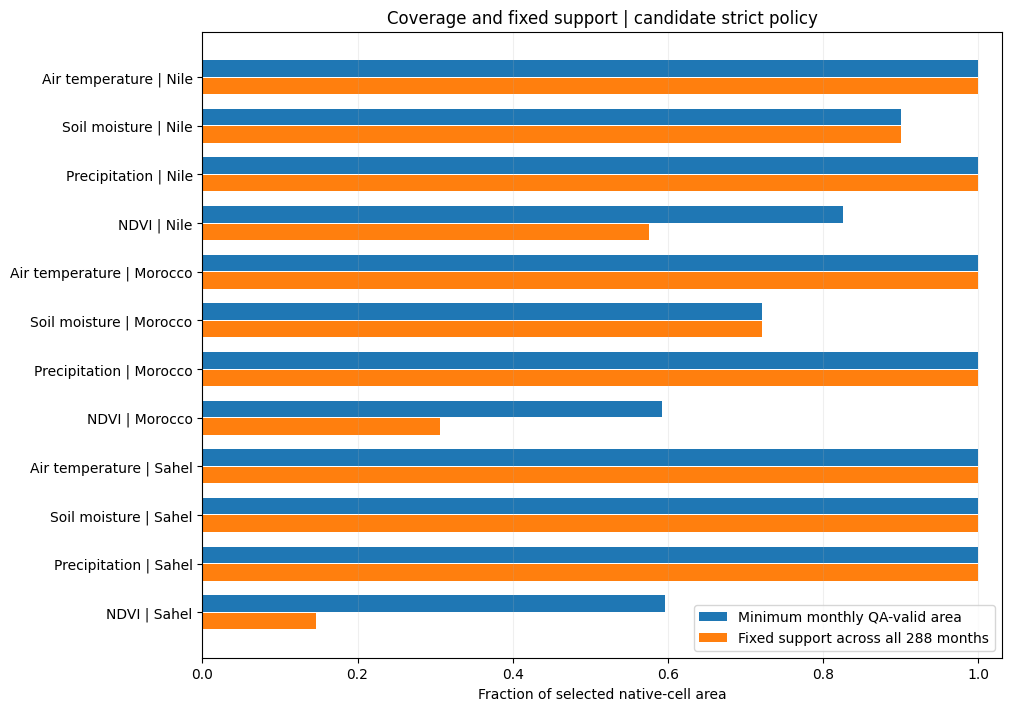

In [2]:
entries = report["entries"]
y = np.arange(len(entries))
fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.barh(y - 0.18, [e["qa_valid_area_fraction_reference_min"] for e in entries], height=0.34, label="Minimum monthly QA-valid area")
ax.barh(y + 0.18, [e["fixed_support_area_fraction_of_selected_native_cells"] for e in entries], height=0.34, label="Fixed support across all 288 months")
ax.set_yticks(y, [f"{labels[e['variable_id']]} | {region_labels[e['region_id']]}" for e in entries])
ax.invert_yaxis()
ax.set_xlim(0, 1.03)
ax.set_xlabel("Fraction of selected native-cell area")
ax.set_title("Coverage and fixed support | candidate strict policy")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
fig.savefig(output / "coverage_summary.png", dpi=140)
display(fig)
plt.close(fig)

Coverage changes are explicit. The regional series uses the fixed subset, not a changing set of available cells. The subset can be geographically unrepresentative. Fractions below refer to selected native-cell area; the bbox selects cell centres, with full-cell spherical weights and no exact polygon intersection.

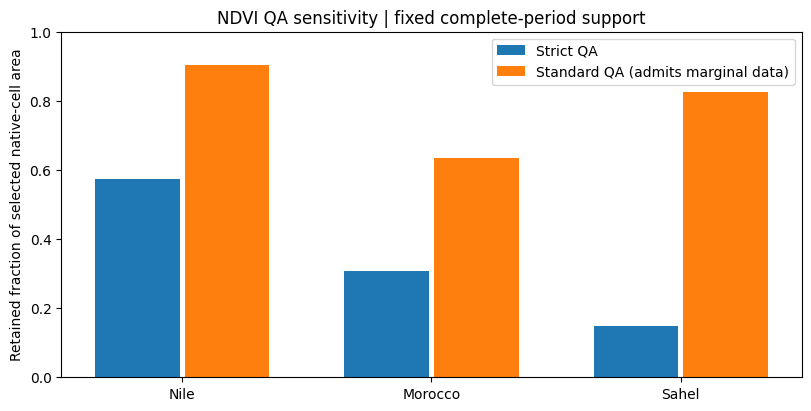

In [3]:
strict = {e["region_id"]:e for e in entries if e["variable_id"] == "vegetation_greenness"}
standard = {e["region_id"]:e for e in comparison["entries"]}
regions = list(strict)
x = np.arange(len(regions))
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.bar(x - 0.18, [strict[r]["fixed_support_area_fraction_of_selected_native_cells"] for r in regions], width=0.34, label="Strict QA")
ax.bar(x + 0.18, [standard[r]["fixed_support_area_fraction_of_selected_native_cells"] for r in regions], width=0.34, label="Standard QA (admits marginal data)")
ax.set_xticks(x, [region_labels[r] for r in regions])
ax.set_ylim(0, 1)
ax.set_ylabel("Retained fraction of selected native-cell area")
ax.set_title("NDVI QA sensitivity | fixed complete-period support")
ax.legend()
fig.savefig(output / "qa_sensitivity.png", dpi=140)
display(fig)
plt.close(fig)

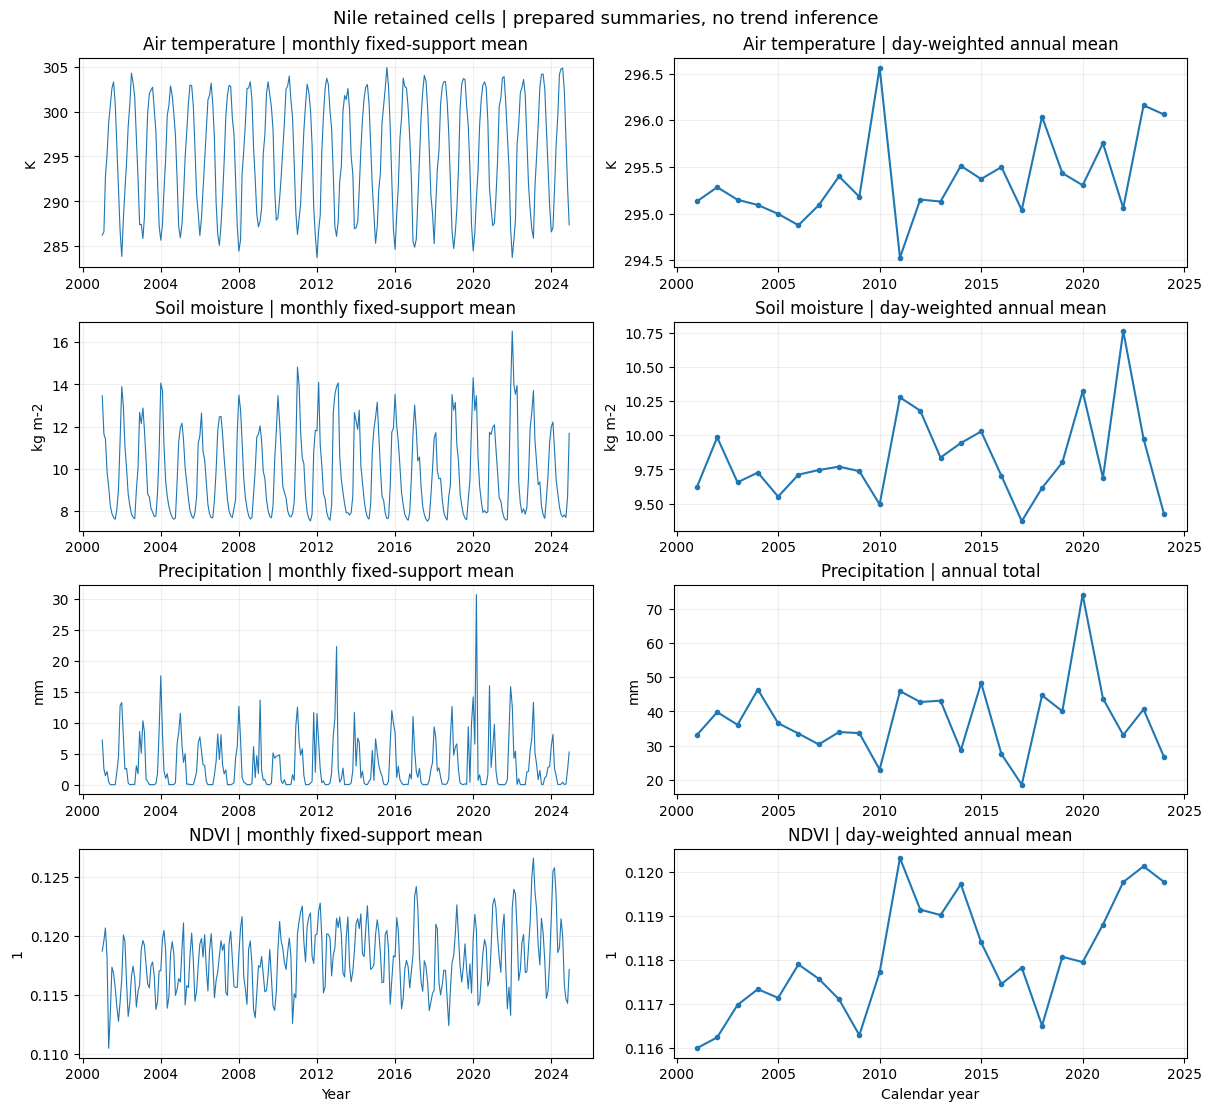

In [4]:
nile = [e for e in entries if e["region_id"] == "nile_corridor"]
fig, axes = plt.subplots(4, 2, figsize=(12, 11), layout="constrained")
for row, entry in enumerate(nile):
    with xr.open_dataset(root / entry["artifact"]) as ds:
        axes[row, 0].plot(ds.time.values, ds.regional_monthly.values, linewidth=0.8)
        axes[row, 1].plot(ds.year.values, ds.regional_annual.values, marker="o", markersize=3)
    axes[row, 0].set_title(f"{labels[entry['variable_id']]} | monthly fixed-support mean")
    annual_label = "annual total" if entry["variable_id"] == "precipitation" else "day-weighted annual mean"
    axes[row, 1].set_title(f"{labels[entry['variable_id']]} | {annual_label}")
    for col in range(2):
        axes[row, col].set_ylabel(entry["monthly_units"])
        axes[row, col].grid(alpha=0.2)
axes[-1, 0].set_xlabel("Year")
axes[-1, 1].set_xlabel("Calendar year")
fig.suptitle("Nile retained cells | prepared summaries, no trend inference", fontsize=13)
fig.savefig(output / "nile_prepared_series.png", dpi=140)
display(fig)
plt.close(fig)

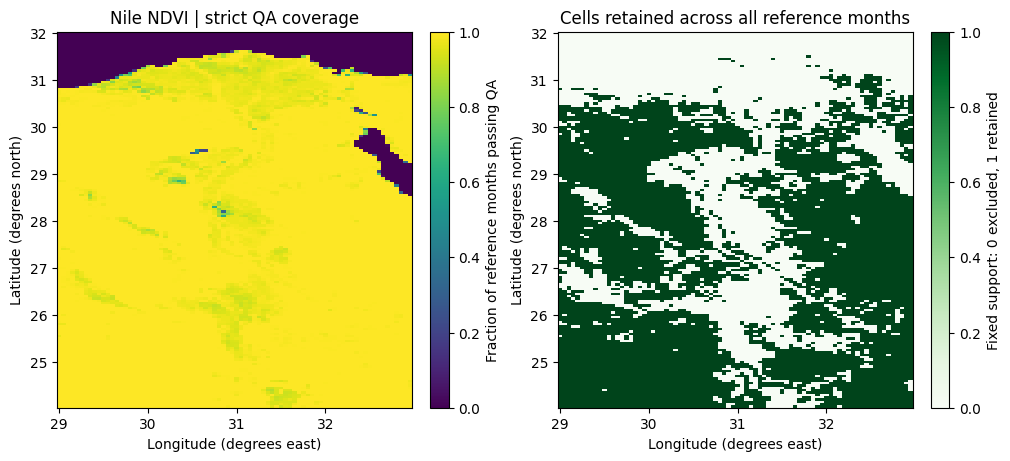

In [5]:
entry = strict["nile_corridor"]
with xr.open_dataset(root / entry["artifact"]) as ds:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
    ds.qa_valid_fraction_by_cell.plot(ax=axes[0], x="lon", y="lat", vmin=0, vmax=1, cmap="viridis", cbar_kwargs={"label":"Fraction of reference months passing QA"})
    ds.fixed_support.plot(ax=axes[1], x="lon", y="lat", vmin=0, vmax=1, cmap="Greens", cbar_kwargs={"label":"Fixed support: 0 excluded, 1 retained"})
    axes[0].set_title("Nile NDVI | strict QA coverage")
    axes[1].set_title("Cells retained across all reference months")
    for ax in axes:
        ax.set_xlabel("Longitude (degrees east)")
        ax.set_ylabel("Latitude (degrees north)")
    fig.savefig(output / "nile_ndvi_support.png", dpi=140)
    display(fig)
    plt.close(fig)

## What is and is not ready

Prepared files retain source ancillary fields, masked monthly values, a fixed-support cell mask, normalized spherical weights, calendar-month anomalies against the full registered reference, and annual summaries. Precipitation source rates are retained separately from monthly amounts. Incomplete years are missing, never scaled up or filled.

The strict-versus-standard comparison is a preparation sensitivity analysis. It is not uncertainty calibration or evidence of a trend. The owner must review the candidate QA/support policy and its spatial exclusions before downstream use. Inference and application readiness flags remain unchanged.